In [82]:
import os, sys
import numpy as np
import pandas as pd
import openpyxl
import torch
from torch import nn
from matplotlib import pyplot as plt
import cv2
import random
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import h5py

## Define Experiment Parameters

In [83]:
is_local = True # todo
model_name = 'mlp'

if is_local:
    sys.path.append(r'C:/Users/w37262do/Documents/git/IR_preprocessing')
else:
    sys.path.append(r'/mnt/iusers01/eee01/w37262do/scratch/IR_preprocessing')
from src.utils import ir_spectra_dataset, adjust_learning_rate
from src.models import MLP

In [84]:
# Experiment
seed = int(sys.argv[1]) if not is_local else 10447201
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)
gen = torch.Generator()
gen.manual_seed(seed)
device = 'cpu'

# Data
wavenumbers = np.load(r"G:\test_dir\qcl2026_processed/wavenumbers.npy" if is_local else './wavenumbers.npy')
num_wavenumbers = len(wavenumbers)
input_image_dims = np.array([num_wavenumbers, 360, 360])
annotation_class_colors = np.array([[0,255,0],[128,0,128],[255,0,255],[0,0,255],[255,165,0],[255,0,0], [255,255,0]])
annotation_class_names = np.array(['epithelium_n','stroma_n','epithelium_c','stroma_c','corpora_amylacea','blood','immune_inf'])
n_classes = len(annotation_class_names)
standardise_data = bool(int(sys.argv[2])) if not is_local else 0

# Data loading
test_set_fraction = 0.2
val_set_fraction= 0.2
use_augmentation = True
num_workers = 0 if is_local else 6
prefetch_factor = None if is_local else 2
use_augmentation = True

# Training
batch_size = 64
initial_lr = 1e-5 # todo look what these might need to be set to
l2 = 5e-2
max_epochs = 30
warmup_epochs = 3
min_lr = 1e-7
save_best_model = True

## Import Data Sets

In [85]:
h5_aus = h5py.File(r"G:/test_dir/aus_qcl2026_processed/annotated_spectra_dataset.h5" if is_local else r'./aus_qcl2026_processed/annotated_spectra_dataset.h5')
spectra_aus = torch.from_numpy(h5_aus['spectra'][:])
pid_aus = h5_aus['patient_id'][:]
label_aus = h5_aus['tissue_class'][:]
h5_aus.close()

h5_nocl = h5py.File(r"G:/test_dir/qcl2026_processed/annotated_spectra_dataset.h5" if is_local else r'./qcl2026_processed/annotated_spectra_dataset.h5')
spectra_nocl = torch.from_numpy(h5_nocl['spectra'][:])
pid_nocl = h5_nocl['patient_id'][:] + 1000000 # Add offset to patient ID in AUS dataset so no false associations
label_nocl = h5_nocl['tissue_class'][:]
h5_nocl.close()

KeyboardInterrupt: 

## Define Datasets, Dataloaders

In [68]:
unique_pids_nocl = np.unique(pid_nocl)
pids_trainval, pids_test, _, _ = train_test_split(
    unique_pids_nocl, np.zeros_like(unique_pids_nocl), test_size=test_set_fraction, random_state=seed)
pids_train, pids_val, _, _ = train_test_split(
    pids_trainval, np.zeros_like(pids_trainval), test_size=(val_set_fraction/(1-test_set_fraction)), random_state=seed)
where_train = np.where(np.isin(pid_nocl,pids_train))
where_val = np.where(np.isin(pid_nocl,pids_val))
where_test = np.where(np.isin(pid_nocl,pids_test))

print(f"Spectra per data split:\n\tTRAIN: {len(where_train[0])}\n\tVAL: {len(where_val[0])}\n\tTEST: {len(where_test[0])}")
print(f"Independent cohort: {len(pid_aus)}")

Spectra per data split:
	TRAIN: 587634
	VAL: 229613
	TEST: 294277
Independent cohort: 1527064


In [69]:
dataset_train = ir_spectra_dataset(
    spectra_nocl[where_train],label_nocl[where_train],annotation_class_names,annotation_class_colors,generator=gen
)
dataset_val = ir_spectra_dataset(
    spectra_nocl[where_val],label_nocl[where_val],annotation_class_names,annotation_class_colors,generator=gen
)
dataset_test = ir_spectra_dataset(
    spectra_nocl[where_test],label_nocl[where_test],annotation_class_names,annotation_class_colors,generator=gen
)
dataset_aus = ir_spectra_dataset(
    spectra_aus,label_aus,annotation_class_names,annotation_class_colors,generator=gen
)

# todo do I need to use a weighted sampler
train_loader = torch.utils.data.DataLoader(dataset_train, batch_size=batch_size, shuffle=True,drop_last=True, generator=gen, num_workers=num_workers, prefetch_factor=prefetch_factor)
val_loader = torch.utils.data.DataLoader(dataset_val, batch_size=batch_size, shuffle=True,drop_last=False, generator=gen, num_workers=num_workers, prefetch_factor=prefetch_factor)
test_loader = torch.utils.data.DataLoader(dataset_test, batch_size=batch_size,shuffle=False,drop_last=False, generator=gen, num_workers=num_workers, prefetch_factor=prefetch_factor)
aus_loader = torch.utils.data.DataLoader(dataset_aus, batch_size=batch_size,shuffle=False,drop_last=False, generator=gen, num_workers=num_workers, prefetch_factor=prefetch_factor)
print(f"loader sizes:\n\ttrain: {len(train_loader)}\n\tval: {len(val_loader)}\n\ttest: {len(test_loader)}")
print(f"Independent cohort: {len(aus_loader)}")

loader sizes:
	train: 9181
	val: 3588
	test: 4599
Independent cohort: 23861


In [70]:
train_mean = spectra_nocl[where_train].mean(0).reshape(1,-1).to(device)
train_std = spectra_nocl[where_train].mean(0).reshape(1,-1).to(device)

def norm(batch):
    if standardise_data:
        batch -= train_mean
        batch /= train_std
    return batch

## Define Model

In [71]:
model = MLP(num_wavenumbers, n_classes)
model = model.to(device)
model.eval()

MLP(
  (bn1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=405, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=512, bias=True)
  (fc3): Linear(in_features=512, out_features=7, bias=True)
  (activation): GELU(approximate='none')
  (classifier): Sequential(
    (0): Linear(in_features=405, out_features=512, bias=True)
    (1): GELU(approximate='none')
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): GELU(approximate='none')
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Linear(in_features=512, out_features=7, bias=True)
  )
)

## Train Loop

In [72]:
optimiser = torch.optim.AdamW(
    model.parameters(),
    lr=initial_lr,
    weight_decay=l2,
    betas=(0.9, 0.999)
)
loss_fn = nn.CrossEntropyLoss()

training_losses,validation_losses = [],[]
training_accs,validation_accs = [],[]
training_f1ms,validation_f1ms = [],[]
training_f1s,validation_f1s = [],[]
learning_rates = []
best_val_f1 = 0
best_val_epoch = 0

In [73]:
for epoch in range(max_epochs):
    curr_lr = adjust_learning_rate(optimiser, epoch, max_epochs, warmup_epochs, initial_lr, min_lr)
    learning_rates.append(curr_lr)
    print(f"\n ON EPOCH {epoch + 1}/{max_epochs} | LR = {curr_lr}")

    # reset running metrics
    running_loss_train, running_loss_val = 0, 0
    train_preds, train_targets = [], []
    val_preds, val_targets = [], []

    # Train loop
    model.train()
    for batch_idx, (data, label) in enumerate(train_loader):

        # Put data and label on device
        data = data.to(device); label = label.to(device)
        data = norm(data)

        # Push data through model
        optimiser.zero_grad()
        out = model(data)

        # Calculate loss
        loss = loss_fn(out, label)
        loss.backward()  # backprop
        optimiser.step()

        # Calculate metrics
        running_loss_train += loss.cpu().item()
        preds = out.argmax(dim=1)  # predicted values on annotated pixels
        train_preds.extend(preds.detach().cpu().numpy())
        train_targets.extend(label.detach().cpu().numpy())

    # Validate loop
    model.eval()
    with torch.no_grad():
        for batch_idx, (data, label) in enumerate(val_loader):

            # Put data and label on device
            data = data.to(device); label = label.to(device)
            data = norm(data)

            # Push data through model
            optimiser.zero_grad()
            out = model(data)

            # Calculate loss
            loss = loss_fn(out, label)

            # Calculate metrics
            running_loss_val += loss.cpu().item()
            preds = out.argmax(dim=1)  # predicted values on annotated pixels
            val_preds.extend(preds.detach().cpu().numpy())
            val_targets.extend(label.detach().cpu().numpy())

    # calculate epoch metrics for train set
    train_acc = accuracy_score(train_targets, train_preds); training_accs.append(train_acc)
    train_f1m = f1_score(train_targets, train_preds, average='macro'); training_f1ms.append(train_f1m)
    train_f1 = f1_score(train_targets, train_preds, average=None); training_f1s.append(train_f1)
    train_loss = running_loss_train / (len(dataset_train));
    training_losses.append(train_loss)

    # calculate epoch metrics for val set
    val_acc = accuracy_score(val_targets, val_preds); validation_accs.append(val_acc)
    val_f1m = f1_score(val_targets, val_preds, average='macro'); validation_f1ms.append(val_f1m)
    val_f1 = f1_score(val_targets, val_preds, average=None); validation_f1s.append(val_f1)
    val_loss = running_loss_val / (len(dataset_val));
    validation_losses.append(val_loss)

    # Update
    print(f"TRAIN --- | Loss: {train_loss:.4} | OA: {train_acc:.4} | f1: {train_f1m:.4}")
    print(f"VAL ----- | Loss: {val_loss:.4} | OA: {val_acc:.4} | f1: {val_f1m:.4}")

    # If performance on validation set best so far, save model
    if val_f1m > best_val_f1:
        best_val_f1 = val_f1m
        best_val_epoch = epoch
        if not is_local:
            torch.save(
                model.state_dict(),
                rf'./{model_name}_weights_{seed}.pt'
            )


 ON EPOCH 1/20 | LR = 0.0
TRAIN --- | Loss: 0.03444 | OA: 0.127 | f1: 0.08917
VAL ----- | Loss: 0.03372 | OA: 0.166 | f1: 0.09723

 ON EPOCH 2/20 | LR = 3.3333333333333337e-06
TRAIN --- | Loss: 0.02049 | OA: 0.5522 | f1: 0.2722
VAL ----- | Loss: 0.01732 | OA: 0.5576 | f1: 0.2746

 ON EPOCH 3/20 | LR = 6.6666666666666675e-06
TRAIN --- | Loss: 0.01263 | OA: 0.6903 | f1: 0.4941
VAL ----- | Loss: 0.01385 | OA: 0.6234 | f1: 0.5203

 ON EPOCH 4/20 | LR = 1e-05
TRAIN --- | Loss: 0.01024 | OA: 0.74 | f1: 0.679
VAL ----- | Loss: 0.01208 | OA: 0.6581 | f1: 0.6002

 ON EPOCH 5/20 | LR = 9.915716843435315e-06
TRAIN --- | Loss: 0.009364 | OA: 0.7593 | f1: 0.7253
VAL ----- | Loss: 0.01152 | OA: 0.6636 | f1: 0.6266

 ON EPOCH 6/20 | LR = 9.66573753555156e-06
TRAIN --- | Loss: 0.008931 | OA: 0.7689 | f1: 0.7449
VAL ----- | Loss: 0.01119 | OA: 0.6728 | f1: 0.6492

 ON EPOCH 7/20 | LR = 9.258574821861592e-06
TRAIN --- | Loss: 0.008609 | OA: 0.7762 | f1: 0.7587
VAL ----- | Loss: 0.01139 | OA: 0.6607 | f

In [74]:
if save_best_model and not is_local: # if saving best model, we want to load the best model now for evaluation
    model.load_state_dict(
        torch.load(
            rf'./{model_name}_weights_{seed}.pt' if not is_local else rf'../model_weights/{model_name}_weights_{seed}.pt',
            weights_only=True)
    )
model.eval()

MLP(
  (bn1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=405, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=512, bias=True)
  (fc3): Linear(in_features=512, out_features=7, bias=True)
  (activation): GELU(approximate='none')
  (classifier): Sequential(
    (0): Linear(in_features=405, out_features=512, bias=True)
    (1): GELU(approximate='none')
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): GELU(approximate='none')
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Linear(in_features=512, out_features=7, bias=True)
  )
)

## Test Loop

In [75]:
# Test - NOCL
running_loss_test = 0
test_preds, test_targets = [], []
model.eval()
with torch.no_grad():
    for batch_idx, (data, label) in enumerate(test_loader):
        # Put data and label on device
        data = data.to(device); label = label.to(device)
        data = norm(data)

        # Push data through model
        optimiser.zero_grad()
        out = model(data)

        # Calculate loss
        loss = loss_fn(out, label)

        # Calculate metrics
        running_loss_test += loss.cpu().item()
        preds = out.argmax(dim=1)  # predicted values on annotated pixels
        test_preds.extend(preds.detach().cpu().numpy())
        test_targets.extend(label.detach().cpu().numpy())

# calculate test set metrics
test_acc = accuracy_score(test_targets, test_preds)
test_f1m = f1_score(test_targets, test_preds, average='macro')
test_f1 = f1_score(test_targets, test_preds, average=None)
test_loss = running_loss_test / len(dataset_test)

In [76]:
# Test - NOCL
aus_running_loss_test = 0
aus_test_preds, aus_test_targets = [], []
model.eval()
with torch.no_grad():
    for batch_idx, (data, label) in enumerate(aus_loader):
        # Put data and label on device
        data = data.to(device); label = label.to(device)
        data = norm(data)

        # Push data through model
        optimiser.zero_grad()
        out = model(data)

        # Calculate loss
        loss = loss_fn(out, label)

        # Calculate metrics
        aus_running_loss_test += loss.cpu().item()
        preds = out.argmax(dim=1)  # predicted values on annotated pixels
        aus_test_preds.extend(preds.detach().cpu().numpy())
        aus_test_targets.extend(label.detach().cpu().numpy())

# calculate test set metrics
aus_test_acc = accuracy_score(aus_test_targets, aus_test_preds)
aus_test_f1m = f1_score(aus_test_targets, aus_test_preds, average='macro')
aus_test_f1 = f1_score(aus_test_targets, aus_test_preds, average=None)
aus_test_loss = aus_running_loss_test / len(dataset_aus)

In [77]:
print(f"TEST (NOCL) ---- | Loss: {test_loss:.4} | OA: {test_acc:.4} | f1: {test_f1m:.4}")
for cls_idx, f1 in enumerate(test_f1):
    print(f"{annotation_class_names[cls_idx]}{(20 - len(annotation_class_names[cls_idx])) * ' '} : {f1:.4}")

print(f"TEST (AUS) ----- | Loss: {aus_test_loss:.4} | OA: {aus_test_acc:.4} | f1: {aus_test_f1m:.4}")
for cls_idx, f1 in enumerate(aus_test_f1):
    print(f"{annotation_class_names[cls_idx]}{(20 - len(annotation_class_names[cls_idx])) * ' '} : {f1:.4}")

TEST (NOCL) ---- | Loss: 0.00761 | OA: 0.8164 | f1: 0.7262
epithelium_n         : 0.854
stroma_n             : 0.8518
epithelium_c         : 0.7915
stroma_c             : 0.2934
corpora_amylacea     : 0.8892
blood                : 0.9924
immune_inf           : 0.4108
TEST (AUS) ----- | Loss: 0.01379 | OA: 0.6001 | f1: 0.5734
epithelium_n         : 0.5987
stroma_n             : 0.7473
epithelium_c         : 0.4793
stroma_c             : 0.1989
corpora_amylacea     : 0.9155
blood                : 0.643
immune_inf           : 0.4309


## Evaluate Training Process

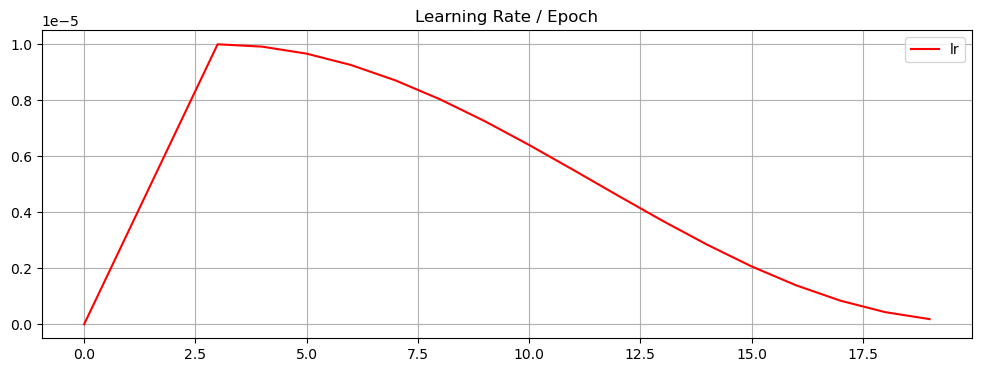

In [78]:
fig,ax = plt.subplots(figsize=(12,4))
ax.plot(np.arange(0,len(learning_rates)),learning_rates,color='red',label="lr")
ax.legend(); ax.grid(); ax.set_title("Learning Rate / Epoch")
if not is_local:
    plt.savefig(f'./lr_curves_{model_name}_{seed}.png')
    plt.close(fig)

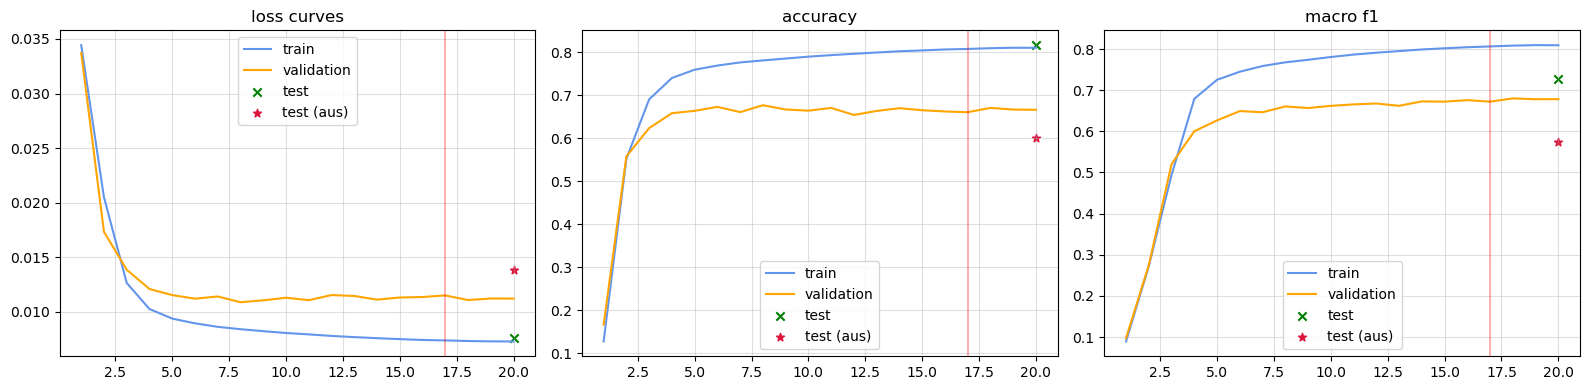

In [79]:
# Plot overall performance curves per-epoch
fig,ax = plt.subplots(1,3,figsize=(16,4))
ax[0].plot(np.arange(1,len(training_losses)+1),np.array(training_losses),color='cornflowerblue',label="train")
ax[0].plot(np.arange(1,len(validation_losses)+1),np.array(validation_losses),color='orange',label="validation")
ax[0].scatter(len(validation_losses),test_loss,color='green',label="test",marker="x")
ax[0].scatter(len(validation_losses),aus_test_loss,color='crimson',label="test (aus)",marker="*")
ax[0].set_title("loss curves"); ax[0].legend(); ax[0].grid(alpha=0.4)

ax[1].plot(np.arange(1,len(training_accs)+1),np.array(training_accs),color='cornflowerblue',label="train")
ax[1].plot(np.arange(1,len(validation_accs)+1),np.array(validation_accs),color='orange',label="validation")
ax[1].scatter(len(validation_losses),test_acc,color='green',label="test",marker="x")
ax[1].scatter(len(validation_losses),aus_test_acc,color='crimson',label="test (aus)",marker="*")
ax[1].set_title("accuracy"); ax[1].legend(); ax[1].grid(alpha=0.4); ax[1].set_ylim(ymin=0,ymax=1)

ax[2].plot(np.arange(1,len(training_f1ms)+1),np.array(training_f1ms),color='cornflowerblue',label="train")
ax[2].plot(np.arange(1,len(validation_f1ms)+1),np.array(validation_f1ms),color='orange',label="validation")
ax[2].scatter(len(validation_losses),test_f1m,color='green',label="test",marker="x")
ax[2].scatter(len(validation_losses),aus_test_f1m,color='crimson',label="test (aus)",marker="*")
ax[2].set_title("macro f1"); ax[2].legend(); ax[2].grid(alpha=0.4); ax[2].set_ylim(ymin=0,ymax=1)

ax[0].axvline(x=best_val_epoch, ymin=0, ymax=1, color='red',alpha=0.3)
ax[1].axvline(x=best_val_epoch, ymin=0, ymax=1, color='red',alpha=0.3)
ax[2].axvline(x=best_val_epoch, ymin=0, ymax=1, color='red',alpha=0.3)

fig.tight_layout()
if not is_local:
    plt.savefig(f'./loss_curves_{model_name}_{seed}.png')
    plt.close(fig)

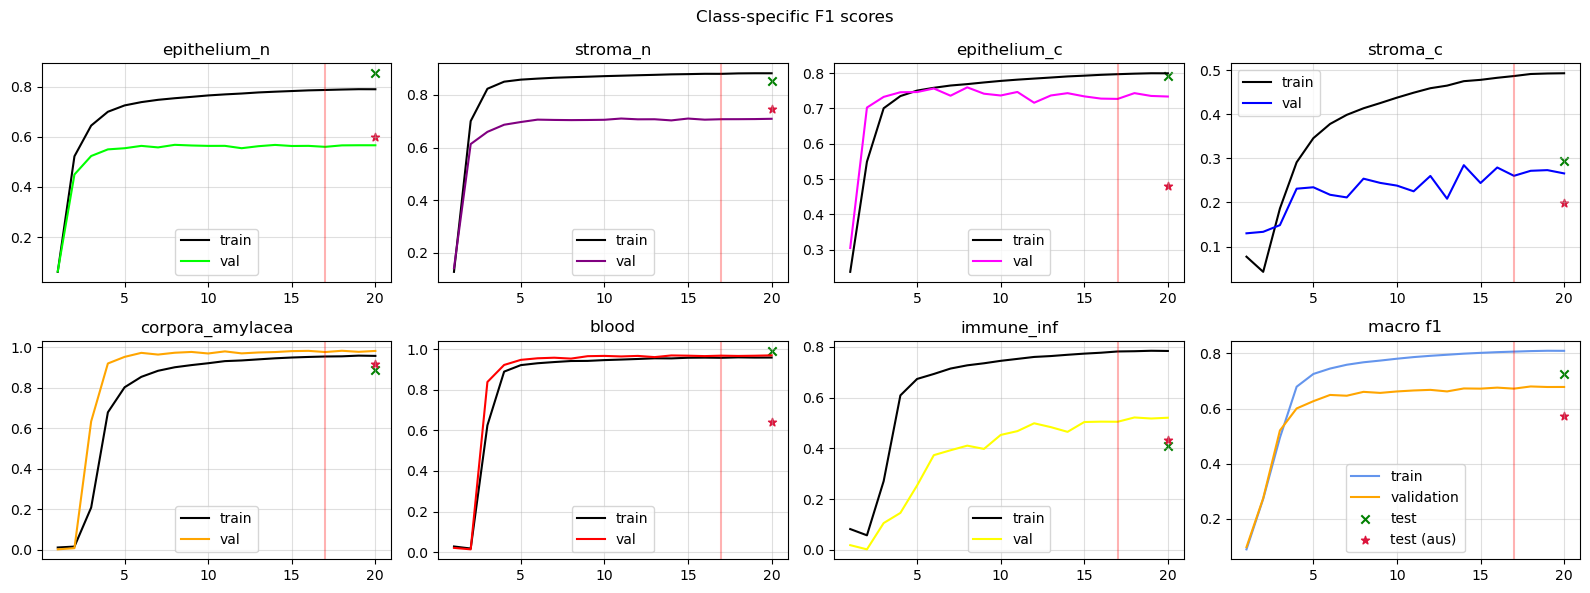

In [80]:
# Plot per-class f1 score curves
fig,ax = plt.subplots(2,4,figsize=(16,6)); ax = ax.flatten()
for cls in range(7):
    ax[cls].plot(np.arange(1,len(training_f1s)+1),[i[cls] for i in training_f1s], color='black', label="train")
    ax[cls].plot(np.arange(1,len(validation_f1s)+1),[i[cls] for i in validation_f1s], color=annotation_class_colors[cls]/255, label="val")
    ax[cls].set_title(f"{annotation_class_names[cls]}")
    ax[cls].legend()
    ax[cls].scatter(len(validation_losses),test_f1[cls],color='green',label="test",marker="x")
    ax[cls].scatter(len(validation_losses),aus_test_f1[cls],color='crimson',label="test (aus)",marker="*")
    ax[cls].axvline(x=best_val_epoch, ymin=0, ymax=1, color='red',alpha=0.3)
    ax[cls].grid(alpha=0.4)
    ax[cls].set_ylim(ymin=0,ymax=1)
ax[7].plot(np.arange(1,len(training_f1ms)+1),np.array(training_f1ms),color='cornflowerblue',label="train")
ax[7].plot(np.arange(1,len(validation_f1ms)+1),np.array(validation_f1ms),color='orange',label="validation")
ax[7].scatter(len(validation_losses),test_f1m,color='green',label="test",marker="x")
ax[7].scatter(len(validation_losses),aus_test_f1m,color='crimson',label="test (aus)",marker="*")
ax[7].axvline(x=best_val_epoch, ymin=0, ymax=1, color='red',alpha=0.3); ax[7].set_title("macro f1"); ax[7].legend()
ax[7].grid(alpha=0.4)
ax[7].set_ylim(ymin=0,ymax=1)
fig.suptitle("Class-specific F1 scores")
plt.tight_layout()
if not is_local:
    plt.savefig(f'./loss_curves_byclass_{model_name}_{seed}.png')
    plt.close(fig)

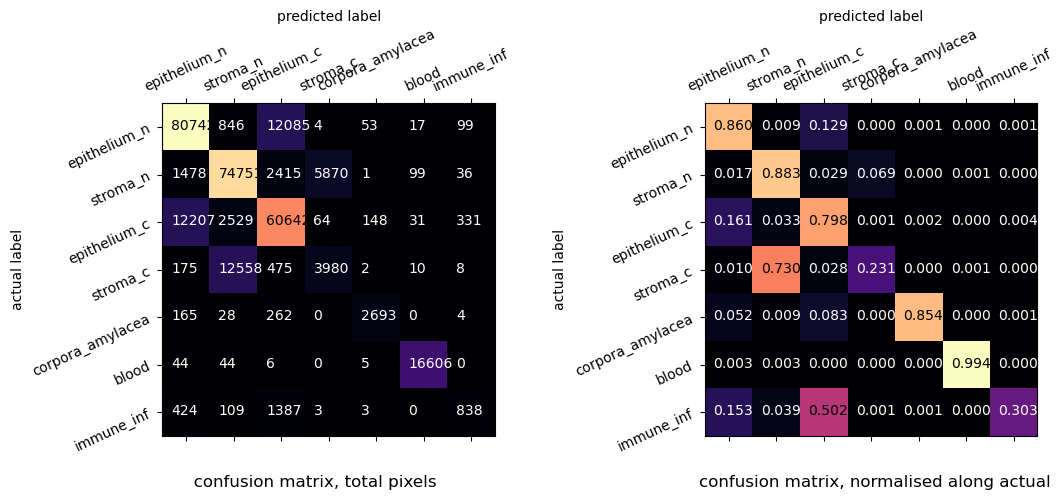

In [81]:
# Normalised such that each 'actual label' column sums to 1. Each entry is thus the fraction of actual label predicted correctly
cm = confusion_matrix(test_targets, test_preds, labels=np.arange(0,n_classes))
cm_norm = confusion_matrix(test_targets, test_preds, labels=np.arange(0,n_classes), normalize='true')
roffset = 0.07; coffset = -0.32

fig,ax = plt.subplots(1,2, figsize=(11,5))
ax[0].matshow(cm,cmap='magma',aspect=1); ax[1].matshow(cm_norm,cmap='magma',aspect=1)
for x in range(2):
    ax[x].set_xticks(np.arange(0, n_classes),labels=annotation_class_names,rotation=25)
    ax[x].set_yticks(np.arange(0, n_classes),labels=annotation_class_names,rotation=25)
    ax[x].set_xlabel("predicted label"); ax[x].xaxis.set_label_position("top"); ax[x].set_ylabel("actual label")
for r in range(n_classes):
    for c in range(n_classes):
        ax[0].text(y=r+roffset,x=c+coffset,s=f'{cm[r,c]}',fontdict={'fontsize':10,'color':"k" if cm[r,c] > cm.max()/2 else "w"})
        ax[1].text(y=r+roffset,x=c+coffset,s=f'{cm_norm[r,c]:.3f}',fontdict={'fontsize':10,'color':"k" if cm_norm[r,c] > 0.5 else "w"})
fig.supxlabel(f"{' '*35}confusion matrix, total pixels{' '*50}confusion matrix, normalised along actual"); fig.tight_layout()
if not is_local:
    plt.savefig(f'./confusion_{model_name}_{seed}.png')
    plt.close(fig)

## Save Model and Results

In [58]:
# Save model
if not is_local:
    torch.save(
        model.state_dict(),
        rf'./{model_name}_weights_{seed}.pt'
    )

    # Save mean and std of data
    torch.save(
        train_mean.cpu(),
        rf'./{model_name}_train_mean_{seed}.pt'
    )
    torch.save(
        train_std.cpu(),
        rf'./{model_name}_train_std_{seed}.pt'
    )

# save results
if not is_local:
    # NOCL
    if os.path.isfile(f'results_NOCL_{model_name}.txt'):
        f = open(f'results_NOCL_{model_name}.txt', 'r')
        lines = f.readlines()
        f.close()
    else:
        lines = [x + ', \n' for x in ['seed', *annotation_class_names, 'overall_acc', 'macro_f1']]

    # Process files
    lines[0] = lines[0].replace('\n', str(seed) + ', \n')
    for cls in range(n_classes):
        lines[cls + 1] = lines[cls + 1].replace('\n', str(test_f1[cls]) + ', \n')
    lines[n_classes + 1] = lines[n_classes + 1].replace('\n', str(test_acc) + ', \n')
    lines[n_classes + 2] = lines[n_classes + 2].replace('\n', str(test_f1m) + ', \n')

    f = open(f'results_NOCL_{model_name}.txt', 'w')
    f.write(''.join(lines))
    f.close()

    # AUS
    if os.path.isfile(f'results_AUS_{model_name}.txt'):
        f = open(f'results_AUS_{model_name}.txt', 'r')
        lines = f.readlines()
        f.close()
    else:
        lines = [x + ', \n' for x in ['seed', *annotation_class_names, 'overall_acc', 'macro_f1']]

    # Process files
    lines[0] = lines[0].replace('\n', str(seed) + ', \n')
    for cls in range(n_classes):
        lines[cls + 1] = lines[cls + 1].replace('\n', str(aus_test_f1[cls]) + ', \n')
    lines[n_classes + 1] = lines[n_classes + 1].replace('\n', str(aus_test_acc) + ', \n')
    lines[n_classes + 2] = lines[n_classes + 2].replace('\n', str(aus_test_f1m) + ', \n')

    f = open(f'results_AUS_{model_name}.txt', 'w')
    f.write(''.join(lines))
    f.close()